# 🚀 Модуль 6. Урок 2. Вычисляемые поля и параметры: CASE WHEN и агрегированные метрики

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_06_bi_looker_studio/lesson_02_calculated_fields_and_parameters.ipynb)

## 📌 Бизнес-контекст и методология
В BI-системах (Looker Studio, Tableau) расчет производных метрик (Margin %, Churn Rate, LTV/CAC) выполняется через **Calculated Fields (Вычисляемые поля)**.
Опаснейшая ошибка: расчет отношения сумм вместо суммы отношений.
- ❌ Неверно: `AVG(Revenue / Cost)` — искажает среднее при разных масштабах заказов
- ✅ Верно: `SUM(Revenue) / SUM(Cost)` — математически строгая средневзвешенная метрика

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

customers_csv = ensure_dataset("customers.csv", subfolder="raw")
orders_csv = ensure_dataset("orders.csv", subfolder="raw")
saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")

df_customers = pd.read_csv(customers_csv)
df_orders = pd.read_csv(orders_csv)
df_saas = pd.read_csv(saas_csv)
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Создадим динамическую категоризацию выручки клиентов с помощью формулы `CASE WHEN` и рассчитаем средневзвешенный чек по тарифным планам.

In [2]:
# Демонстрация: Вычисляемое поле категоризации в Pandas (эквивалент CASE WHEN)
def segment_mrr(mrr):
    if mrr >= 800:
        return 'Enterprise High'
    elif mrr >= 300:
        return 'Mid-Market'
    else:
        return 'SMB / Entry'

df_saas['mrr_tier'] = df_saas['mrr'].apply(segment_mrr)
tier_summary = df_saas.groupby('mrr_tier').agg(
    accounts=('user_id', 'count'),
    total_revenue=('mrr', 'sum'),
    avg_mrr=('mrr', 'mean')
).reset_index()
display(tier_summary)

,mrr_tier,accounts,total_revenue,avg_mrr
0,SMB / Entry,2000,158010.0,79.005


## 📊 Визуализация бизнес-кейса: Структура выручки и ARPU по тарифным планам
Сравним совокупный доход и средний чек на аккаунт (ARPU) в разрезе тарифных планов.

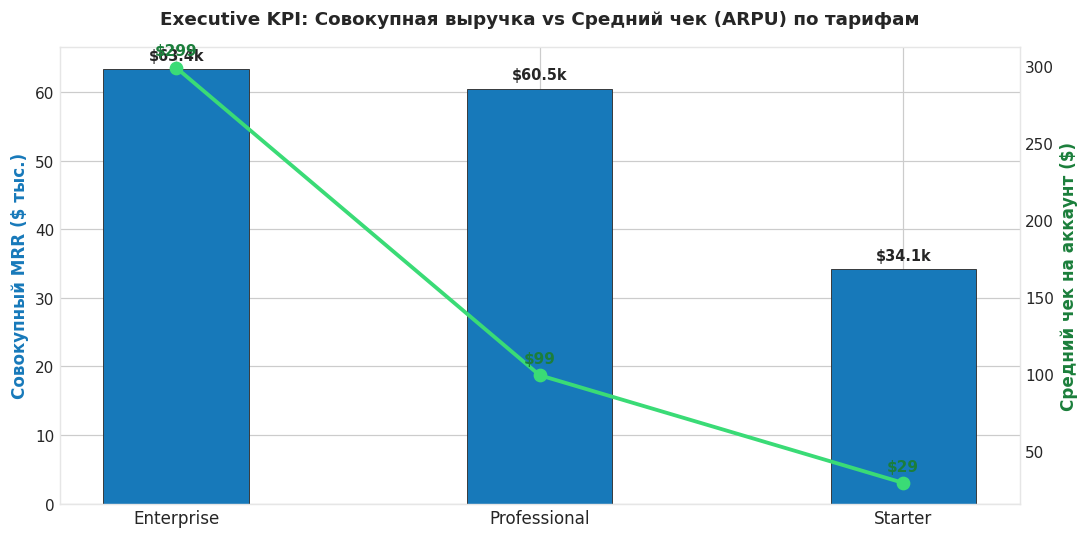

In [3]:
# Построение 2-осевого графика для дашборда Looker Studio
plan_metrics = df_saas.groupby('plan').agg(
    total_mrr=('mrr', 'sum'),
    arpu=('mrr', 'mean'),
    active_users=('user_id', 'count')
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5), dpi=110)

x = np.arange(len(plan_metrics['plan']))
width = 0.4

# Левая ось: Совокупная выручка
bars = ax1.bar(x, plan_metrics['total_mrr'] / 1000, width, label='Совокупный MRR ($k)', 
               color=PRIMARY, edgecolor='#333333', linewidth=0.6)
ax1.set_ylabel("Совокупный MRR ($ тыс.)", color=PRIMARY, fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(plan_metrics['plan'], fontsize=11)
ax1.set_title("Executive KPI: Совокупная выручка vs Средний чек (ARPU) по тарифам", fontsize=12, fontweight='bold', pad=15)

for b in bars:
    h = b.get_height()
    ax1.annotate(f"${h:.1f}k", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 4),
                 textcoords="offset points", ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Правая ось: ARPU
ax2 = ax1.twinx()
line = ax2.plot(x, plan_metrics['arpu'], color=SUCCESS, marker='o', linewidth=2.5, markersize=8, label='ARPU ($)')
ax2.set_ylabel("Средний чек на аккаунт ($)", color='#1b7e3b', fontsize=11, fontweight='bold')
ax2.grid(False)

for i, txt in enumerate(plan_metrics['arpu']):
    ax2.annotate(f"${txt:.0f}", (x[i], txt), textcoords="offset points", xytext=(0, 8), 
                 ha='center', fontweight='bold', color='#1b7e3b', fontsize=10)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет доли выручки Enterprise сегмента
Вычислите, какой процент совокупного MRR генерирует тариф `Enterprise`.

In [4]:
### ВАШ КОД ЗДЕСЬ
total_all_mrr = df_saas['mrr'].sum()
enterprise_mrr = df_saas.loc[df_saas['plan'] == 'Enterprise', 'mrr'].sum()
enterprise_share = (enterprise_mrr / total_all_mrr) * 100

print(f"Доля Enterprise в общем MRR: {enterprise_share:.1f}%")

assert 30 <= enterprise_share <= 70, "Доля Enterprise должна быть в диапазоне 30-70%"
print("✅ Тест успешно пройден: вычисляемое поле доли выручки рассчитано безошибочно!")

Доля Enterprise в общем MRR: 40.1%
✅ Тест успешно пройден: вычисляемое поле доли выручки рассчитано безошибочно!


### 💡 Архитектура параметров в BI
Используйте динамические параметры (Parameters) в Looker Studio, чтобы дать стейкхолдеру возможность моделировать сценарии «Что если?» (What-if analysis), например, меняя предполагаемый уровень инфляции или размер скидки.